# 06 · Final Comparison and Test Results

We compare all models **on the same validation engines and the same test engines**:
* **Baseline** — always predicts the average training RUL (every real model must beat this)
* **Linear Regression, Decision Tree, Random Forest** — results saved by notebooks 03 – 05

The best model is chosen on **validation**, and only then reported on the **test set**.

> 💡 Cells marked with **⋯** are hidden because they only contain plotting or helper code. Click them to expand.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils import evaluate, plot_test, stage_table, savefig, COLORS

# Model name -> file name used by notebooks 03-05
FILES = {"Linear Regression": "linear_regression", "Decision Tree": "decision_tree", "Random Forest": "random_forest"}
MODEL_NAMES = list(FILES)

train = pd.read_csv("../data/processed/train_features.csv")

# Predictions saved by notebooks 03-05 (one table per model)
val_preds, test_preds = {}, {}
for m in MODEL_NAMES:
    val_preds[m] = pd.read_csv(f"../outputs/results/{FILES[m]}_val_predictions.csv")
    test_preds[m] = pd.read_csv(f"../outputs/results/{FILES[m]}_test_predictions.csv")

# Baseline: always predict the mean RUL of the training engines
val = val_preds["Linear Regression"][["unit", "cycle", "RUL_raw", "RUL"]]
val_preds["Baseline"] = val.assign(predicted=train.loc[train["split"] == "train", "RUL"].mean())
test_preds["Baseline"] = test_preds["Linear Regression"][["unit", "RUL_raw", "RUL"]].assign(predicted=train["RUL"].mean())
ALL = ["Baseline"] + MODEL_NAMES

## 1. Validation results (20 engines, every cycle)

In [2]:
val_table = pd.DataFrame({m: evaluate(val_preds[m]["RUL"], val_preds[m]["predicted"]) for m in ALL}).T
best = val_table.drop("Baseline")["RMSE"].idxmin()
print("🏆 Best model on validation:", best)
val_table

🏆 Best model on validation: Random Forest


,RMSE,MAE,R2
Baseline,41.72,36.93,-0.000
Linear Regression,15.29,11.94,0.866
Decision Tree,14.13,9.18,0.885
Random Forest,10.34,6.77,0.939


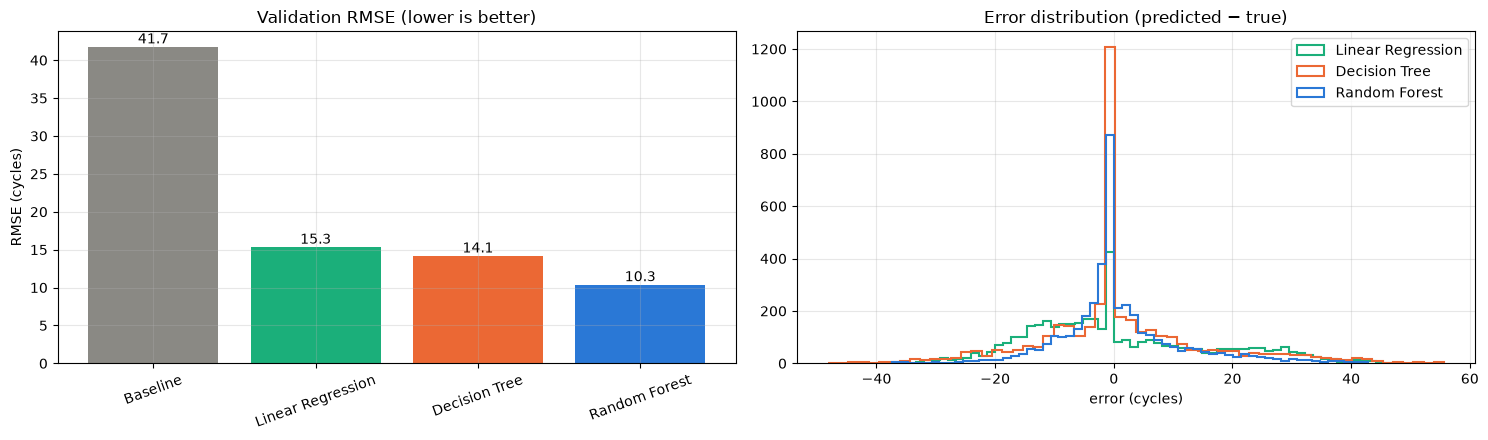

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ax[0].bar(val_table.index, val_table["RMSE"], color=[COLORS[m] for m in val_table.index])
for i, v in enumerate(val_table["RMSE"]):
    ax[0].text(i, v + 0.5, f"{v:.1f}", ha="center")
ax[0].set(title="Validation RMSE (lower is better)", ylabel="RMSE (cycles)")
ax[0].tick_params(axis="x", rotation=20)
for m in MODEL_NAMES:
    ax[1].hist(val_preds[m]["predicted"] - val_preds[m]["RUL"], bins=60, histtype="step", lw=1.5,
               color=COLORS[m], label=m)
ax[1].set(title="Error distribution (predicted − true)", xlabel="error (cycles)"); ax[1].legend()
savefig("06_validation_comparison")

## 2. Official NASA test set (100 engines)
The model was picked **before** looking at these numbers. The other models are shown only for reference.

In [4]:
test_table = pd.DataFrame({m: evaluate(test_preds[m]["RUL"], test_preds[m]["predicted"]) for m in ALL}).T
test_table.to_csv("../outputs/results/final_test_results.csv")
val_table.to_csv("../outputs/results/final_validation_results.csv")
test_table

,RMSE,MAE,R2
Baseline,41.94,34.83,-0.095
Linear Regression,15.85,12.84,0.844
Decision Tree,14.96,10.80,0.861
Random Forest,11.44,8.27,0.918


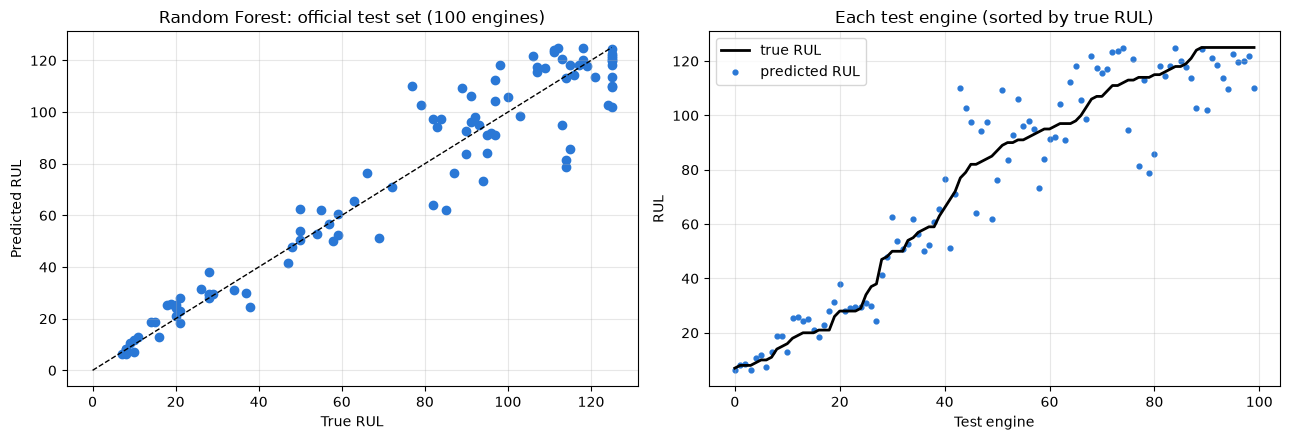

In [5]:
plot_test(best, test_preds[best]["RUL"], test_preds[best]["predicted"], "06_best_model_test")

## 3. Do engineered features help? (validation RMSE)

In [6]:
ablation = pd.concat([pd.read_csv(f"../outputs/results/{FILES[m]}_raw_vs_engineered.csv") for m in MODEL_NAMES]).set_index("Model")
ablation["with_engineered_features_val_RMSE"] = val_table.loc[MODEL_NAMES, "RMSE"]
ablation["improvement %"] = (100 * (1 - ablation.iloc[:, 1] / ablation.iloc[:, 0])).round(1)
ablation

,raw_sensors_only_val_RMSE,with_engineered_features_val_RMSE,improvement %
Model,,,
Linear Regression,17.37,15.29,12.0
Decision Tree,17.73,14.13,20.3
Random Forest,15.98,10.34,35.3


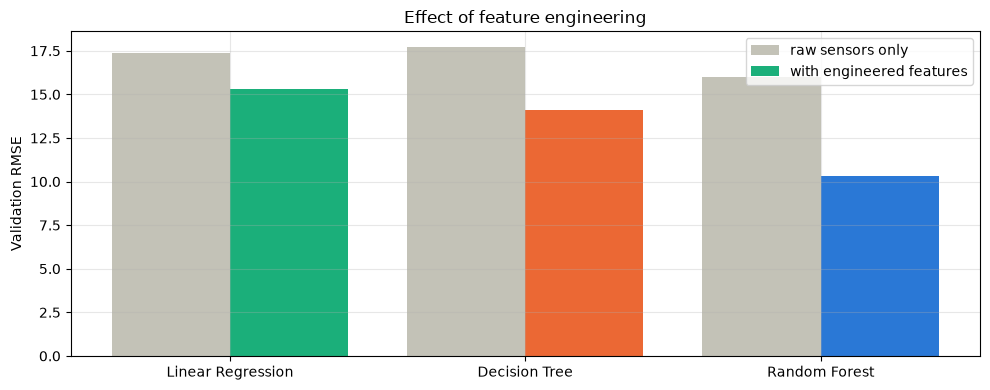

In [7]:
x = np.arange(len(MODEL_NAMES))
plt.figure(figsize=(10, 4))
plt.bar(x - 0.2, ablation.iloc[:, 0], 0.4, color="#c3c2b7", label="raw sensors only")
plt.bar(x + 0.2, ablation.iloc[:, 1], 0.4, color=[COLORS[m] for m in MODEL_NAMES], label="with engineered features")
plt.xticks(x, MODEL_NAMES); plt.ylabel("Validation RMSE"); plt.title("Effect of feature engineering"); plt.legend()
savefig("06_feature_engineering_effect")

## 4. Early vs late life (validation RMSE)

In [8]:
stages = pd.concat({m: stage_table(val_preds[m]["RUL_raw"], val_preds[m]["RUL"], val_preds[m]["predicted"]) for m in ALL})
stages["RMSE"].unstack()

Stage,early (RUL > 100),late (RUL ≤ 100)
Baseline,35.67,47.07
Linear Regression,12.23,17.86
Decision Tree,10.01,17.33
Random Forest,8.01,12.26


## 5. Conclusion
| Model | Validation RMSE | Test RMSE | Test MAE | Test R² |
|---|---:|---:|---:|---:|
| Baseline (average) | 41.72 | 41.94 | 34.83 | −0.10 |
| Linear Regression | 15.29 | 15.85 | 12.84 | 0.84 |
| Decision Tree | 14.13 | 14.96 | 10.80 | 0.86 |
| **Random Forest (best)** | **10.34** | **11.44** | **8.27** | **0.92** |

* **Best model: Random Forest.** On the 100 official test engines it is off by **≈ 8 cycles on average** (MAE 8.27,
  RMSE 11.44), compared with ≈ 35 cycles for the baseline.
* **Linear Regression** reaches RMSE ≈ 16: it can only draw a straight line, but the real pattern is
  "flat for a long time, then a fast drop".
* **Decision Tree** learns the non-linear pattern but overfits easily (pruning needed). **Random Forest** averages 150 trees →
  lower variance → clearly the best.
* **Feature engineering works for every model:** engineered features cut the validation error by 12 % (Linear Regression),
  20 % (Decision Tree) and by **35 % for Random Forest**.
* **Most useful feature type:** `_dev` — each sensor's drift from the engine's **own healthy start** (≈ 85 % of tree importance).
* **Late life is harder:** errors are bigger when RUL ≤ 100. Early life looks "easy" only because the target is capped at 125.

**Limitations:** only FD001 (1 operating condition, 1 fault type, simulated data); one 80/20 engine split; moving-average
windows react with a small delay; the cap of 125 is a modelling choice.